In [17]:
# =============================================================================
# MODULE 4 — Régularisation Ridge & Lasso : Contrôler l'Overfitting
# =============================================================================


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

In [18]:
# =============================================================================
# 1. DONNÉES
# =============================================================================

import yfinance as yf
spx = yf.download("^GSPC", start="2000-01-01", end="2024-12-31", auto_adjust=True)
vix = yf.download("^VIX",  start="2000-01-01", end="2024-12-31", auto_adjust=True)
spx_close = spx['Close'].squeeze(); vix_close = vix['Close'].squeeze()
log_ret = np.log(spx_close / spx_close.shift(1))
realized_vol = log_ret.rolling(21).std() * np.sqrt(252) * 100
df = pd.DataFrame({'VIX': vix_close, 'RealizedVol': realized_vol}).dropna()


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


In [19]:
# =============================================================================
# 2. FEATURE ENGINEERING — 100 FEATURES (lags 1→50 + delta-lags 1→50)
# =============================================================================
# On passe de 4 features (Module 2/3) à 100 pour illustrer l'overfitting
N_LAGS = 50
lag_features, delta_features = [], []

for k in range(1, N_LAGS + 1):
    col  = f'VIX_lag{k}'
    dcol = f'DVIX_lag{k}'
    df[col]  = df['VIX'].shift(k)
    df[dcol] = df['VIX'].diff(1).shift(k)
    lag_features.append(col)
    delta_features.append(dcol)

all_features  = lag_features + delta_features       # 100 features
core_features = ['VIX_lag1', 'VIX_lag5', 'VIX_lag21', 'DVIX_lag1']  # 4 features M2/3

df = df.dropna()
print(f"Shape : {df.shape}  |  100 features générées")

Shape : (6216, 102)  |  100 features générées


In [20]:
# =============================================================================
# 3. TRAIN / TEST SPLIT + STANDARDISATION
# =============================================================================
split_idx  = int(len(df) * 0.80)
split_date = df.index[split_idx]

X_all  = df[all_features].values
X_core = df[core_features].values
y      = df['RealizedVol'].values

ytr = y[:split_idx];  yte = y[split_idx:]

# IMPORTANT : StandardScaler fitté UNIQUEMENT sur le train
sc_all  = StandardScaler().fit(X_all[:split_idx])
sc_core = StandardScaler().fit(X_core[:split_idx])

Xtr_all  = sc_all.transform(X_all[:split_idx]);   Xte_all  = sc_all.transform(X_all[split_idx:])
Xtr_core = sc_core.transform(X_core[:split_idx]); Xte_core = sc_core.transform(X_core[split_idx:])

print(f"Train : {split_idx} obs ({df.index[0].date()} → {split_date.date()})")
print(f"Test  : {len(df)-split_idx} obs ({split_date.date()} → {df.index[-1].date()})")

Train : 4972 obs (2000-04-14 → 2020-01-22)
Test  : 1244 obs (2020-01-22 → 2024-12-30)


In [21]:
# =============================================================================
# 4. OLS — DÉMONSTRATION DE L'OVERFITTING
# =============================================================================
print("\n=== OLS — Overfitting ===")

ols4 = LinearRegression().fit(Xtr_core, ytr)
r2_ols4_train = r2_score(ytr, ols4.predict(Xtr_core))
r2_ols4_test  = r2_score(yte, ols4.predict(Xte_core))
print(f"OLS  4 features : Train={r2_ols4_train:.4f}  Test={r2_ols4_test:.4f}  GAP={r2_ols4_train-r2_ols4_test:.4f}")

ols = LinearRegression().fit(Xtr_all, ytr)
r2_ols_train = r2_score(ytr, ols.predict(Xtr_all))
r2_ols_test  = r2_score(yte, ols.predict(Xte_all))
print(f"OLS 100 features : Train={r2_ols_train:.4f}  Test={r2_ols_test:.4f}  GAP={r2_ols_train-r2_ols_test:.4f}")
print(f"  ↑ Le GAP augmente avec les features : signe d'overfitting !")


=== OLS — Overfitting ===
OLS  4 features : Train=0.8491  Test=0.7618  GAP=0.0873
OLS 100 features : Train=0.9001  Test=0.8703  GAP=0.0299
  ↑ Le GAP augmente avec les features : signe d'overfitting !


In [22]:
# =============================================================================
# 5. RIDGE — PÉNALITÉ L2
# =============================================================================
print("\n=== Ridge (pénalité L2) ===")
# RidgeCV : cherche le meilleur alpha via CV temporelle automatiquement
tscv = TimeSeriesSplit(n_splits=5)
alphas_grid = np.logspace(-3, 5, 200)

ridge_cv = RidgeCV(alphas=alphas_grid, cv=tscv, scoring='r2')
ridge_cv.fit(Xtr_all, ytr)
best_alpha_ridge = ridge_cv.alpha_
print(f"Meilleur alpha Ridge : {best_alpha_ridge:.2f}")

ridge = Ridge(alpha=best_alpha_ridge)
ridge.fit(Xtr_all, ytr)
r2_ridge_train = r2_score(ytr, ridge.predict(Xtr_all))
r2_ridge_test  = r2_score(yte, ridge.predict(Xte_all))
print(f"Ridge : Train={r2_ridge_train:.4f}  Test={r2_ridge_test:.4f}  GAP={r2_ridge_train-r2_ridge_test:.4f}")
print(f"  Tous les {len(ridge.coef_)} coefficients sont non-nuls (Ridge ne sélectionne pas)")


=== Ridge (pénalité L2) ===
Meilleur alpha Ridge : 0.00
Ridge : Train=0.9001  Test=0.8703  GAP=0.0299
  Tous les 100 coefficients sont non-nuls (Ridge ne sélectionne pas)


In [23]:
# =============================================================================
# 6. LASSO — PÉNALITÉ L1 (avec sélection de features)
# =============================================================================
print("\n=== Lasso (pénalité L1) ===")
lasso_cv = LassoCV(alphas=alphas_grid, cv=tscv, max_iter=10000, n_jobs=-1)
lasso_cv.fit(Xtr_all, ytr)
best_alpha_lasso = lasso_cv.alpha_
print(f"Meilleur alpha Lasso : {best_alpha_lasso:.5f}")

lasso = Lasso(alpha=best_alpha_lasso, max_iter=10000)
lasso.fit(Xtr_all, ytr)
r2_lasso_train = r2_score(ytr, lasso.predict(Xtr_all))
r2_lasso_test  = r2_score(yte, lasso.predict(Xte_all))
n_active = np.sum(lasso.coef_ != 0)
print(f"Lasso : Train={r2_lasso_train:.4f}  Test={r2_lasso_test:.4f}  GAP={r2_lasso_train-r2_lasso_test:.4f}")
print(f"  Features actives (coef != 0) : {n_active} / {len(all_features)}")

# Features sélectionnées par Lasso
active_feats = [(all_features[i], lasso.coef_[i])
                for i in range(len(all_features)) if lasso.coef_[i] != 0]
print("\n  Features sélectionnées par Lasso :")
for feat, coef in sorted(active_feats, key=lambda x: abs(x[1]), reverse=True):
    print(f"    {feat:15s} : {coef:+.4f}")


=== Lasso (pénalité L1) ===
Meilleur alpha Lasso : 0.00100
Lasso : Train=0.9001  Test=0.8702  GAP=0.0299
  Features actives (coef != 0) : 55 / 100

  Features sélectionnées par Lasso :
    VIX_lag1        : +1.9414
    VIX_lag50       : -0.9100
    VIX_lag8        : +0.9056
    VIX_lag3        : +0.8813
    VIX_lag10       : +0.8421
    VIX_lag9        : +0.8014
    VIX_lag2        : +0.7949
    VIX_lag5        : +0.7879
    VIX_lag6        : +0.7588
    VIX_lag7        : +0.6882
    VIX_lag12       : +0.6875
    VIX_lag4        : +0.6456
    VIX_lag16       : +0.6110
    VIX_lag13       : +0.5399
    VIX_lag14       : +0.4989
    VIX_lag15       : +0.4903
    VIX_lag11       : +0.4004
    VIX_lag29       : -0.3658
    DVIX_lag20      : +0.3577
    VIX_lag31       : -0.3223
    VIX_lag33       : -0.3205
    DVIX_lag21      : +0.3085
    VIX_lag30       : -0.2899
    VIX_lag28       : -0.2670
    DVIX_lag22      : +0.2493
    VIX_lag42       : -0.2449
    DVIX_lag19      : +0.2397
    

In [24]:
# =============================================================================
# 7. CHEMINS DE RÉGULARISATION
# =============================================================================
print("\nCalcul des chemins de régularisation...")
alphas_path = np.logspace(-2, 5, 80)
train_r2_ridge_path, test_r2_ridge_path = [], []
for a in alphas_path:
    m = Ridge(alpha=a).fit(Xtr_all, ytr)
    train_r2_ridge_path.append(r2_score(ytr, m.predict(Xtr_all)))
    test_r2_ridge_path.append(r2_score(yte,  m.predict(Xte_all)))

alphas_lasso_path = np.logspace(-3, 1, 60)
train_r2_lasso_path, test_r2_lasso_path, nonzero_path = [], [], []
for a in alphas_lasso_path:
    m = Lasso(alpha=a, max_iter=5000).fit(Xtr_all, ytr)
    train_r2_lasso_path.append(r2_score(ytr, m.predict(Xtr_all)))
    test_r2_lasso_path.append(r2_score(yte,  m.predict(Xte_all)))
    nonzero_path.append(np.sum(m.coef_ != 0))


Calcul des chemins de régularisation...


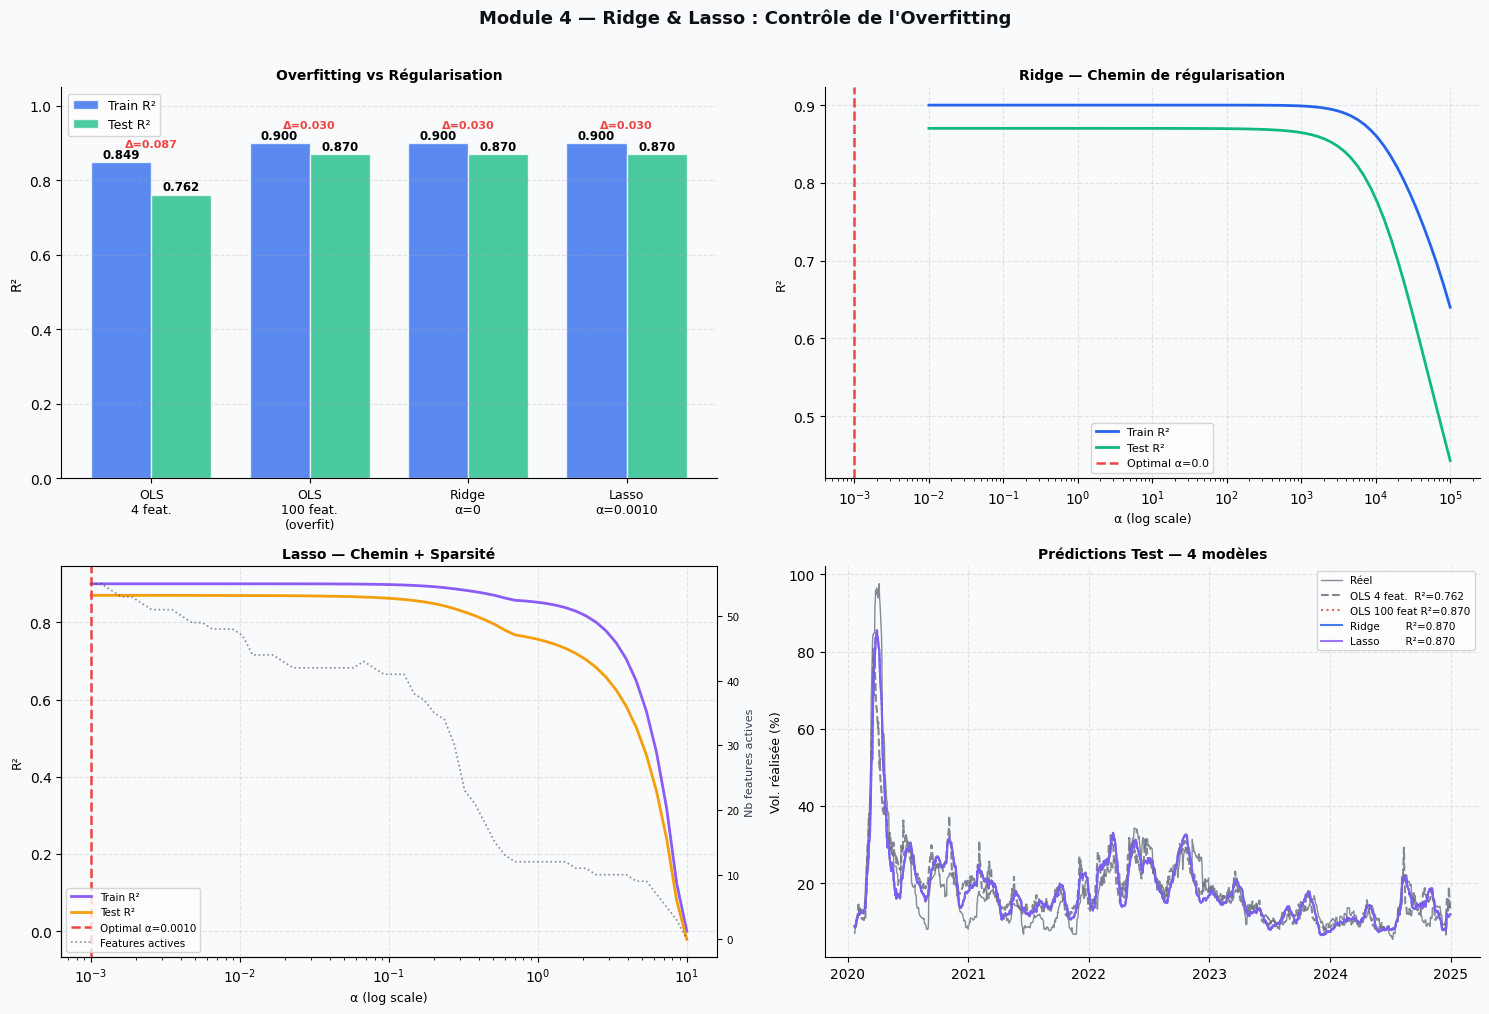


Graphique sauvegardé : module4_results.png


In [25]:
# =============================================================================
# 8. VISUALISATIONS
# =============================================================================
PLT_BG = '#F8FAFC'
fig, axes = plt.subplots(2, 2, figsize=(15, 10), facecolor=PLT_BG)
fig.suptitle('Module 4 — Ridge & Lasso : Contrôle de l\'Overfitting',
             fontsize=13, fontweight='bold', color='#0D1117', y=1.01)

# ── Fig 1 : Comparaison Train vs Test — 4 modèles
ax = axes[0, 0]
model_labels = ['OLS\n4 feat.', 'OLS\n100 feat.\n(overfit)', 
                f'Ridge\nα={best_alpha_ridge:.0f}', f'Lasso\nα={best_alpha_lasso:.4f}']
train_r2s = [r2_ols4_train, r2_ols_train, r2_ridge_train, r2_lasso_train]
test_r2s  = [r2_ols4_test,  r2_ols_test,  r2_ridge_test,  r2_lasso_test]
x_pos = np.arange(len(model_labels))
w = 0.38
b1 = ax.bar(x_pos - w/2, train_r2s, w, color='#2563EB', alpha=0.75, label='Train R²', edgecolor='white')
b2 = ax.bar(x_pos + w/2, test_r2s,  w, color='#10B981', alpha=0.75, label='Test R²',  edgecolor='white')
for bar, val in zip(list(b1) + list(b2), train_r2s + test_r2s):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.004,
            f'{val:.3f}', ha='center', va='bottom', fontsize=8.5, fontweight='bold')
for i, (tr, te) in enumerate(zip(train_r2s, test_r2s)):
    gap = tr - te
    if gap > 0.01:
        ax.annotate(f'Δ={gap:.3f}', xy=(x_pos[i], max(tr, te) + 0.04),
                    ha='center', fontsize=8, color='#EF4444', fontweight='bold')
ax.set_xticks(x_pos); ax.set_xticklabels(model_labels, fontsize=9)
ax.set_ylabel('R²', fontsize=10)
ax.set_title('Overfitting vs Régularisation', fontsize=10, fontweight='bold')
ax.legend(fontsize=9); ax.set_ylim(0, 1.05)
ax.set_facecolor(PLT_BG); ax.grid(True, alpha=0.3, linestyle='--', axis='y')
ax.spines[['top', 'right']].set_visible(False)

# ── Fig 2 : Ridge regularisation path
ax = axes[0, 1]
ax.semilogx(alphas_path, train_r2_ridge_path, color='#2563EB', lw=2, label='Train R²')
ax.semilogx(alphas_path, test_r2_ridge_path,  color='#10B981', lw=2, label='Test R²')
ax.axvline(best_alpha_ridge, color='#EF4444', lw=1.8, linestyle='--',
           label=f'Optimal α={best_alpha_ridge:.1f}')
ax.set_xlabel('α (log scale)', fontsize=9); ax.set_ylabel('R²', fontsize=9)
ax.set_title('Ridge — Chemin de régularisation', fontsize=10, fontweight='bold')
ax.legend(fontsize=8)
ax.set_facecolor(PLT_BG); ax.grid(True, alpha=0.3, linestyle='--')
ax.spines[['top', 'right']].set_visible(False)

# ── Fig 3 : Lasso regularisation path + sparsité
ax = axes[1, 0]
ax_twin = ax.twinx()
ax.semilogx(alphas_lasso_path, train_r2_lasso_path, color='#8B5CF6', lw=2, label='Train R²')
ax.semilogx(alphas_lasso_path, test_r2_lasso_path,  color='#F59E0B', lw=2, label='Test R²')
ax.axvline(best_alpha_lasso, color='#EF4444', lw=1.8, linestyle='--',
           label=f'Optimal α={best_alpha_lasso:.4f}')
ax_twin.semilogx(alphas_lasso_path, nonzero_path, color='#374151', lw=1.2,
                  linestyle=':', alpha=0.6, label='Features actives')
ax_twin.set_ylabel('Nb features actives', fontsize=8, color='#374151')
ax_twin.tick_params(labelsize=7.5)
ax.set_xlabel('α (log scale)', fontsize=9); ax.set_ylabel('R²', fontsize=9)
ax.set_title('Lasso — Chemin + Sparsité', fontsize=10, fontweight='bold')
lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax_twin.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, fontsize=7.5, loc='lower left')
ax.set_facecolor(PLT_BG); ax.grid(True, alpha=0.3, linestyle='--')
ax.spines[['top', 'right']].set_visible(False)

# ── Fig 4 : Prédictions test set
ax = axes[1, 1]
test_dates = df.index[split_idx:]
ax.plot(test_dates, yte, color='#374151', lw=1.0, alpha=0.6, label='Réel', zorder=1)
for preds, lbl, col, ls in [
    (ols4.predict(Xte_core),      f'OLS 4 feat.  R²={r2_ols4_test:.3f}',  '#6B7280', '--'),
    (ols.predict(Xte_all),        f'OLS 100 feat R²={r2_ols_test:.3f}',   '#EF4444', ':'),
    (ridge.predict(Xte_all),      f'Ridge        R²={r2_ridge_test:.3f}',  '#2563EB', '-'),
    (lasso.predict(Xte_all),      f'Lasso        R²={r2_lasso_test:.3f}',  '#8B5CF6', '-'),
]:
    ax.plot(test_dates, preds, color=col, lw=1.5, linestyle=ls, alpha=0.85, label=lbl)
ax.set_title('Prédictions Test — 4 modèles', fontsize=10, fontweight='bold')
ax.set_ylabel('Vol. réalisée (%)', fontsize=9)
ax.legend(fontsize=7.5, ncol=1)
ax.set_facecolor(PLT_BG); ax.grid(True, alpha=0.3, linestyle='--')
ax.spines[['top', 'right']].set_visible(False)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.tight_layout()
plt.savefig('module4_results.png', dpi=150, bbox_inches='tight')
plt.show()
print("\nGraphique sauvegardé : module4_results.png")

In [26]:
# =============================================================================
# 9. RÉSUMÉ FINAL
# =============================================================================
print("\n" + "="*60)
print("RÉSUMÉ MODULE 4")
print("="*60)
print(f"{'Modèle':<20} {'Train R²':>10} {'Test R²':>10} {'GAP':>8}")
print("-"*50)
for lbl, tr, te in [
    ("OLS 4 feat.",   r2_ols4_train,  r2_ols4_test),
    ("OLS 100 feat.", r2_ols_train,   r2_ols_test),
    (f"Ridge α={best_alpha_ridge:.0f}", r2_ridge_train, r2_ridge_test),
    (f"Lasso α={best_alpha_lasso:.4f}", r2_lasso_train, r2_lasso_test),
]:
    flag = " ⚠️" if tr - te > 0.02 else " ✅"
    print(f"{lbl:<20} {tr:>10.4f} {te:>10.4f} {tr-te:>8.4f}{flag}")
print(f"\nLasso a sélectionné {n_active} features sur {len(all_features)}")
print("Features sélectionnées :", [f for f, _ in active_feats])


RÉSUMÉ MODULE 4
Modèle                 Train R²    Test R²      GAP
--------------------------------------------------
OLS 4 feat.              0.8491     0.7618   0.0873 ⚠️
OLS 100 feat.            0.9001     0.8703   0.0299 ⚠️
Ridge α=0                0.9001     0.8703   0.0299 ⚠️
Lasso α=0.0010           0.9001     0.8702   0.0299 ⚠️

Lasso a sélectionné 55 features sur 100
Features sélectionnées : ['VIX_lag1', 'VIX_lag2', 'VIX_lag3', 'VIX_lag4', 'VIX_lag5', 'VIX_lag6', 'VIX_lag7', 'VIX_lag8', 'VIX_lag9', 'VIX_lag10', 'VIX_lag11', 'VIX_lag12', 'VIX_lag13', 'VIX_lag14', 'VIX_lag15', 'VIX_lag16', 'VIX_lag17', 'VIX_lag28', 'VIX_lag29', 'VIX_lag30', 'VIX_lag31', 'VIX_lag32', 'VIX_lag33', 'VIX_lag35', 'VIX_lag36', 'VIX_lag37', 'VIX_lag38', 'VIX_lag42', 'VIX_lag44', 'VIX_lag45', 'VIX_lag46', 'VIX_lag48', 'VIX_lag49', 'VIX_lag50', 'DVIX_lag17', 'DVIX_lag18', 'DVIX_lag19', 'DVIX_lag20', 'DVIX_lag21', 'DVIX_lag22', 'DVIX_lag23', 'DVIX_lag24', 'DVIX_lag25', 'DVIX_lag26', 'DVIX_lag33', 'DVIX_